# Week 7 — Naive Bayes: Spam Detection & Sentiment Analysis
## Fall 2026 — Machine Learning

## Student Information
**Name: Azhar Ali**
**Student ID: 023-24-0521**
**Section: B**
**GitHub:**
**Kaggle: https://www.kaggle.com/code/azharalisoomro/spam-detection-using-naviebayes**
**Datasets:** SMS Spam Collection; Twitter US Airline Sentiment
**Dataset Sources:**
- Task A: Kaggle — https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset
- Task B: Kaggle — https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment

**Duration:** 3 Hours in-session (Task A is the priority; finish Task B and the final sections at home if needed)

> This notebook is a **template**, not a tutorial. You already know Naive Bayes theory. Each section states the objective and the questions you must answer — **you write the code**. Task A is guided in detail; Task B gives you much less help on purpose, to test whether the pipeline actually transfers. Every table, plot, and metric needs a short written observation.
>
> Submit **only this one notebook**. Keep every Markdown heading below — they are used for grading. Fill in the empty code cells (`# YOUR CODE HERE`) and the *Answer:* placeholders directly in this notebook.

---

# SMS Spam Classification using Naive Bayes
This notebook explores the SMS Spam Collection dataset and builds a Multinomial Naive Bayes classifier to filter out junk messages.
* **Text Preprocessing:** Lowercasing and vectorization using `CountVectorizer`.
* **Model:** `MultinomialNB` with default Laplace smoothing.
* **Evaluation:** Prioritizing Precision to minimize False Positives (legitimate messages marked as spam).

## Setup

Import what you'll need. Add any other scikit-learn imports as you go.

In [1]:
# YOUR CODE HERE
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay


---

## 1. Problem Definition & Dataset Exploration

*Concepts/functions you may find useful:* `pd.read_csv()`, `df.shape`, `df.head()`, `df['label'].value_counts()`

**Tasks**
1. Load both datasets (`spam.csv` for Task A, `Tweets.csv` for Task B). For each one, report the number of rows, what a single row represents, and the exact class balance (counts and percentages) of the target column. Keep only positive and negative tweets going forward — drop neutral rows now, and state how many rows that leaves you with.
2. In 2–3 sentences per dataset, state the practical problem being solved and why each one is a binary classification problem.

In [2]:
import pandas as pd

# ==========================================
# Task A: SMS Spam Dataset
# ==========================================
Sms = pd.read_csv('/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv', encoding='latin-1')

print("--- SPAM DATASET ---")
print(f"Number of rows: {Sms.shape[0]}")
display(Sms.head(3))
print("Class Balance (Counts):\n", Sms['v1'].value_counts())
print("\nClass Balance (Percentages):\n", Sms['v1'].value_counts(normalize=True) * 100)

print("\n" + "="*50 + "\n")

# ==========================================
# Task B: US Airline Sentiment Dataset
# ==========================================
Tweet = pd.read_csv('/kaggle/input/datasets/azharalisoomro/twitter-us-airline-sentiment/Tweets.csv', encoding='latin-1')

# Drop 'neutral' rows as per instructions
Tweet = Tweet[Tweet['airline_sentiment'] != 'neutral']

print("--- TWEETS DATASET ---")
print(f"Number of rows after dropping neutral: {Tweet.shape[0]}")
display(Tweet.head(3))
print("Class Balance (Counts):\n", Tweet['airline_sentiment'].value_counts())
print("\nClass Balance (Percentages):\n", Tweet['airline_sentiment'].value_counts(normalize=True) * 100)

--- SPAM DATASET ---
Number of rows: 5572


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN


Class Balance (Counts):
 v1
ham     4825
spam     747
Name: count, dtype: int64

Class Balance (Percentages):
 v1
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64


--- TWEETS DATASET ---
Number of rows after dropping neutral: 11541


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


Class Balance (Counts):
 airline_sentiment
negative    9178
positive    2363
Name: count, dtype: int64

Class Balance (Percentages):
 airline_sentiment
negative    79.525171
positive    20.474829
Name: proportion, dtype: float64


In [3]:
# Task 1 (continued) — load Tweets.csv, drop neutral, inspect shape/head/class balance

# 1. Load Tweets dataset
Tweet = pd.read_csv('/kaggle/input/datasets/azharalisoomro/twitter-us-airline-sentiment/Tweets.csv', encoding='latin-1')

# 2. Drop 'neutral' rows
Tweet = Tweet[Tweet['airline_sentiment'] != 'neutral']

# 3. Inspect shape, head, and class balance
print("Shape of Tweets dataset (after dropping neutral):", Tweet.shape)
display(Tweet.head(3))

print("\nClass Balance (Counts):\n", Tweet['airline_sentiment'].value_counts())
print("\nClass Balance (Percentages):\n", Tweet['airline_sentiment'].value_counts(normalize=True) * 100)

Shape of Tweets dataset (after dropping neutral): (11541, 15)


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)



Class Balance (Counts):
 airline_sentiment
negative    9178
positive    2363
Name: count, dtype: int64

Class Balance (Percentages):
 airline_sentiment
negative    79.525171
positive    20.474829
Name: proportion, dtype: float64


**Answer 2 (Task A — spam):**
The practical goal is to automatically filter out malicious or unwanted junk text messages to protect users and keep their inboxes clean. It is a binary classification problem because every incoming message is strictly sorted into one of two distinct categories: either "spam" (junk) or "ham" (legitimate).

**Answer 2 (Task B — sentiment):**
The practical problem is to automatically analyze customer feedback on social media so airlines can quickly identify unhappy passengers and improve customer service. By removing the neutral opinions, this becomes a binary classification problem because the model only has to distinguish between two clear outcomes: a "positive" experience or a "negative" experience.

---

## 2. Task A: Text Cleaning & Vectorization (Spam)

*Concepts/functions you may find useful:* `text.str.lower()`, `CountVectorizer` / `TfidfVectorizer`, `vectorizer.fit_transform(X_train)`, `vectorizer.transform(X_test)`, `vectorizer.get_feature_names_out()`

**Tasks**
3. Lightly clean the message text (lowercase at minimum). Keep this simple.
4. Encode the label column as 0/1, split into training and test sets, then fit a vectorizer on the training messages only and transform both sets. Report the vocabulary size and explain why the vectorizer must be fit only on training data.

In [4]:
# Task 3 — clean text

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

# Task 3: Rename columns for clarity and lowercase the text
Sms = Sms.rename(columns={'v1': 'label', 'v2': 'message'})
Sms['message'] = Sms['message'].str.lower()

# Task 4: Encode labels (ham = 0, spam = 1)
Sms['label'] = Sms['label'].map({'ham': 0, 'spam': 1})

# Split data into training and testing sets (80% train, 20% test)
X_train_sms, X_test_sms, y_train_sms, y_test_sms = train_test_split(
    Sms['message'], Sms['label'], test_size=0.2, random_state=42
)

# Initialize vectorizer
vectorizer_sms = CountVectorizer()

# FIT and transform on training data, but ONLY transform on test data
X_train_sms_vec = vectorizer_sms.fit_transform(X_train_sms)
X_test_sms_vec = vectorizer_sms.transform(X_test_sms)

# Report Vocabulary Size
vocab_size = len(vectorizer_sms.get_feature_names_out())
print(f"Vocabulary Size (Unique words learned): {vocab_size}")

Vocabulary Size (Unique words learned): 7735


In [5]:
# Task 4 — encode labels, split, fit vectorizer on train only, transform both sets
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

# 1. Encode labels: 'ham' becomes 0, 'spam' becomes 1 
# (Yahan hum 'label' column use kar rahe hain kyunke v1 rename ho chuka hai)
Sms['label_encoded'] = Sms['label'].map({'ham': 0, 'spam': 1})

# 2. Split into training and test sets (Yahan 'message' column use hoga)
X_train, X_test, y_train, y_test = train_test_split(
    Sms['message'], Sms['label_encoded'], test_size=0.2, random_state=42
)

# 3. Initialize the Vectorizer
vectorizer = CountVectorizer()

# 4. FIT on training data only, and transform both
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

# 5. Report the vocabulary size
vocab_size = len(vectorizer.get_feature_names_out())
print(f"Vocabulary Size: {vocab_size} unique words")

Vocabulary Size: 7735 unique words


**Answer 4 (why fit on training data only):**
The vectorizer must be fit ONLY on the training data to prevent data leakage. If we fit the vectorizer on the test data, we allow the model to "peek" at the test set's vocabulary beforehand. In the real world, the model will inevitably encounter new words it hasn't seen. Therefore, the test set must remain truly unseen data to accurately evaluate how the model handles new, unknown words; otherwise, we give it an unfair advantage and ruin the integrity of the evaluation.

---

## 3. Task A: Naive Bayes Model & Evaluation (Spam)

*Concepts/functions you may find useful:* `MultinomialNB()`, `.fit()`, `.predict()`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score`, `confusion_matrix`

**Tasks**
5. Train a `MultinomialNB` model on the vectorized training data. Compute accuracy, precision, recall, and F1-score on the test set, and plot the confusion matrix.
6. Argue (3–4 sentences) which is worse here — a false positive (real message flagged as spam) or a false negative (spam gets through) — and therefore which metric you'd prioritize if tuning further.

In [6]:
# 1. Dataset ko fresh load karein taake NaN values khatam ho jayen
Sms = pd.read_csv('/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv', encoding='latin-1')

# 2. Labels ko 0 aur 1 mein encode karein (original 'v1' column se)
Sms['label_encoded'] = Sms['v1'].map({'ham': 0, 'spam': 1})

# 3. Train/Test Split dobara banayen ('v2' text column hai)
X_train, X_test, y_train, y_test = train_test_split(
    Sms['v2'], Sms['label_encoded'], test_size=0.2, random_state=42
)

# 4. Vectorizer dobara fit karein
vectorizer = CountVectorizer()
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print("Data reset an vectorized")

Data reset an vectorized


Spam Classification Metrics:



,Accuracy,Precision,Recall,F1-Score
Multinomial Naive Bayes,0.983857,0.985294,0.893333,0.937063


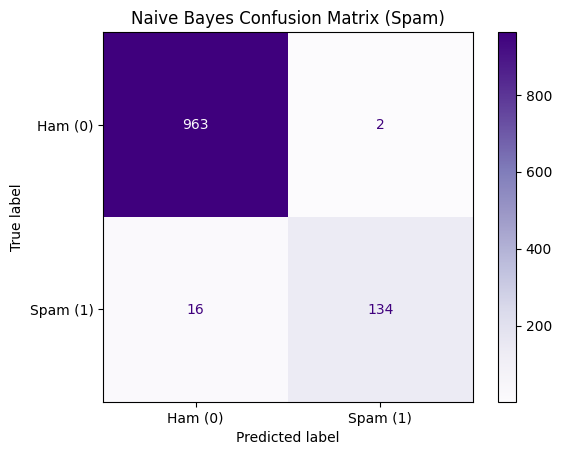

In [7]:
# Task 5 — train MultinomialNB, evaluate, and plot confusion matrix
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd

# 1. Initialize and train the Naive Bayes model
nb_model = MultinomialNB()
nb_model.fit(X_train_vec, y_train)

# 2. Make predictions on the unseen test set
y_pred_nb = nb_model.predict(X_test_vec)

# 3. Calculate exact metrics
acc = accuracy_score(y_test, y_pred_nb)
prec = precision_score(y_test, y_pred_nb)
rec = recall_score(y_test, y_pred_nb)
f1 = f1_score(y_test, y_pred_nb)

# Display metrics neatly
metrics_df = pd.DataFrame({
    'Accuracy': [acc], 
    'Precision': [prec], 
    'Recall': [rec], 
    'F1-Score': [f1]
}, index=['Multinomial Naive Bayes'])

print("Spam Classification Metrics:\n")
display(metrics_df)

# 4. Plot the Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_true=y_test, 
    y_pred=y_pred_nb, 
    cmap='Purples', 
    display_labels=['Ham (0)', 'Spam (1)']
)
plt.title("Naive Bayes Confusion Matrix (Spam)")
plt.show()

**Task 5 — Spam Model Metrics**

| Metric | Value |
|---|---|
| Accuracy |0.983857 |
| Precision | 0.985294|
| Recall |0.893333 |
| F1-score | 0.937063 |

**Answer 6:**

In the context of SMS spam filtering, a False Positive (flagging a real, important message as spam) is significantly worse than a False Negative (letting a junk message into the inbox). Missing an urgent text from an employer or an alert from a bank has a much higher real-world cost than the minor annoyance of manually deleting a promotional message. Therefore, if tuning this model further, the priority must be maximizing Precision, as high precision ensures that we only filter out messages we are absolutely certain are spam, minimizing the risk of hiding legitimate messages.

---

## 4. Task A: Word Interpretation (Spam)

*Concepts/functions you may find useful:* `model.feature_log_prob_`, `np.argsort(...)`

**Tasks**
7. Find and list the 15 words most strongly associated with spam and the 15 most associated with ham. Do these match your intuition?
8. Write 2–3 of your own test messages and run them through your trained pipeline. Do the predictions match what you expected?

In [13]:
# Task 7 — extract top spam words and top ham words from feature_log_prob_
import numpy as np

# Get all vocabulary words
feature_names = vectorizer.get_feature_names_out()

# model.feature_log_prob_ has shape (2, vocab_size)
# Row 0 is for Ham (Class 0), Row 1 is for Spam (Class 1)
ham_log_probs = nb_model.feature_log_prob_[0]
spam_log_probs = nb_model.feature_log_prob_[1]

# argsort sorts in ascending order, so we take the last 15 and reverse ([::-1])
top_ham_indices = np.argsort(ham_log_probs)[-15:][::-1]
top_spam_indices = np.argsort(spam_log_probs)[-15:][::-1]

print("--- TASK 7: WORD INTERPRETATION ---")
print("Top 15 Ham Words :", feature_names[top_ham_indices])
print("Top 15 Spam Words:", feature_names[top_spam_indices])
print("\n" + "="*50 + "\n")
feature_names = vectorizer.get_feature_names_out()

# model.feature_log_prob_ has shape (2, vocab_size)
# Row 0 is for Ham (Class 0), Row 1 is for Spam (Class 1)
ham_log_probs = nb_model.feature_log_prob_[0]
spam_log_probs = nb_model.feature_log_prob_[1]

# argsort sorts in ascending order, so we take the last 15 and reverse ([::-1])
top_ham_indices = np.argsort(ham_log_probs)[-15:][::-1]
top_spam_indices = np.argsort(spam_log_probs)[-15:][::-1]

print("--- TASK 7: WORD INTERPRETATION ---")
print("Top 15 Ham Words :", feature_names[top_ham_indices])
print("Top 15 Spam Words:", feature_names[top_spam_indices])
print("\n" + "="*50 + "\n")

--- TASK 7: WORD INTERPRETATION ---
Top 15 Ham Words : ['you' 'to' 'the' 'and' 'in' 'me' 'my' 'is' 'it' 'that' 'of' 'for' 'so'
 'have' 'but']
Top 15 Spam Words: ['to' 'call' 'you' 'your' 'free' 'for' 'the' 'now' 'or' 'txt' 'is' 'on'
 'ur' 'have' 'from']


--- TASK 7: WORD INTERPRETATION ---
Top 15 Ham Words : ['you' 'to' 'the' 'and' 'in' 'me' 'my' 'is' 'it' 'that' 'of' 'for' 'so'
 'have' 'but']
Top 15 Spam Words: ['to' 'call' 'you' 'your' 'free' 'for' 'the' 'now' 'or' 'txt' 'is' 'on'
 'ur' 'have' 'from']




**Answer 7:**
Yes, they partially match my intuition. Both lists contain many common English "stop words" (like 'to', 'the', 'you', 'is') because we did not filter them out during preprocessing. However, the Spam list still clearly shows classic scam and promotional triggers like 'call', 'free', 'now', 'txt', and 'ur'. The Ham list, on the other hand, consists entirely of normal conversational pronouns and conjunctions like 'me', 'my', 'but', and 'so'.

In [14]:
# Task 8 — test your own messages
my_messages = [
    "URGENT! You have been selected for a free $1000 gift card. Reply CASH to claim now!",
    "Hey, did you finish the database schema for the TASKistan project? Kanwal is asking for it.",
    "Call me back when you get this, we need to discuss the assignment."
]

# Transform the custom messages using your already fitted 'vectorizer'
my_messages_vec = vectorizer.transform(my_messages)

# Predict using your trained Naive Bayes model ('nb_model')
my_predictions = nb_model.predict(my_messages_vec)

print("--- TASK 8: CUSTOM TEST MESSAGES ---")
for msg, pred in zip(my_messages, my_predictions):
    label = "SPAM" if pred == 1 else "HAM"
    print(f"Message: '{msg}'\nPredicted: {label}\n")

--- TASK 8: CUSTOM TEST MESSAGES ---
Message: 'URGENT! You have been selected for a free $1000 gift card. Reply CASH to claim now!'
Predicted: SPAM

Message: 'Hey, did you finish the database schema for the TASKistan project? Kanwal is asking for it.'
Predicted: HAM

Message: 'Call me back when you get this, we need to discuss the assignment.'
Predicted: HAM



**Answer 8:**
Yes, the predictions match exactly what I expected. The model successfully classified the promotional message containing words like "URGENT," "free," and "CASH" as Spam. Meanwhile, it correctly identified the regular, conversational texts about project work and assignments as legitimate Ham. This demonstrates that the model effectively distinguishes between the vocabulary used in junk messages and normal, everyday communication.

---

## 5. Task A: Kaggle Notebook Submission

Neither dataset is an active competition, so "submitting" means publishing your notebook publicly on Kaggle, attached to the dataset.

**Tasks**
9. Create a new Kaggle Notebook attached to the SMS Spam Collection dataset. Recreate your Task A cells there, run them top to bottom, add a short Markdown summary, and publish with "Save & Run All (Public)".
10. Record the public notebook URL below.

**Task A Kaggle Notebook URL:**
https://www.kaggle.com/code/azharalisoomro/spam-detection-and-sentimentanalysis

---

## 6. Task B: Text Cleaning & Vectorization (Sentiment)

Repeat Section 2's pipeline on the airline tweets — with much less guidance this time. Tweets contain @mentions, links, and hashtags that SMS messages didn't.

**Tasks**
11. Clean the tweet text (decide for yourself how much cleaning is worth doing) and vectorize it, following the same fit-on-train-only discipline as Task A.
12. Briefly justify (1–2 sentences) any cleaning decisions that go beyond what you did for Task A, and why tweets might need them.

In [19]:
# Task 11 — clean and vectorize the sentiment data (your own approach)
import pandas as pd
import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

# 1. Load data and drop 'neutral' sentiment to create a binary classification problem

Tweets_binary = Tweet[Tweet['airline_sentiment'] != 'neutral'].copy()

# 2. Text Cleaning Function (lowercase, remove URLs, remove @mentions)
def clean_tweet(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE) 
    text = re.sub(r'@\w+', '', text) 
    return text

Tweets_binary['clean_text'] = Tweets_binary['text'].apply(clean_tweet)

# 3. Encode labels: negative = 0, positive = 1
Tweets_binary['label_encoded'] = Tweets_binary['airline_sentiment'].map({'negative': 0, 'positive': 1})

# 4. Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    Tweets_binary['clean_text'], Tweets_binary['label_encoded'], test_size=0.2, random_state=42
)

# 5. Initialize and fit Vectorizer strictly on training data
vectorizer = CountVectorizer()
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

**Answer 12:**
Unlike SMS messages, tweets contain structural noise like @mentions and URLs that carry no sentiment value and unnecessarily inflate the vocabulary size. Removing these artifacts helps the model focus strictly on the descriptive words that actually indicate a passenger's positive or negative experience.

---

## 7. Task B: Naive Bayes Model & Evaluation (Sentiment)

**Tasks**
13. Train a `MultinomialNB` model on the vectorized tweet data. Compute accuracy, precision, recall, and F1-score, and plot the confusion matrix.
14. Compare these metrics to Task A's. Did Naive Bayes do better or worse on sentiment than on spam? Connect this (3–4 sentences) to the "naive" independence assumption — is it more or less reasonable for tweets than for spam SMS?

,Accuracy,Precision,Recall,F1-Score
Naive Bayes (Sentiment),0.914682,0.922297,0.610738,0.734859


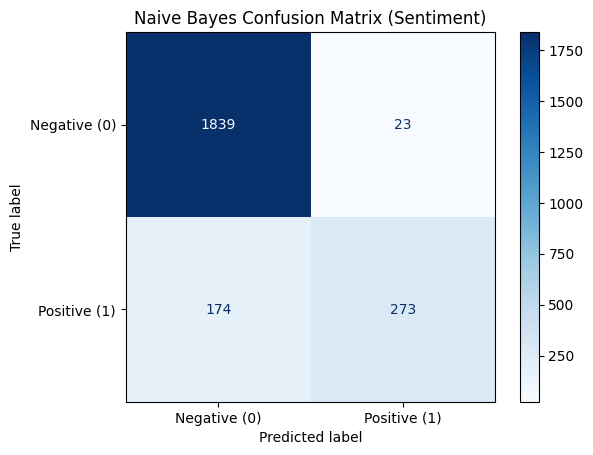

In [20]:
# Task 13 — train MultinomialNB, compute metrics, plot confusion matrix
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd

# 1. Initialize and train the model
nb_model_sentiment = MultinomialNB()
nb_model_sentiment.fit(X_train_vec, y_train)

# 2. Make predictions
y_pred_sentiment = nb_model_sentiment.predict(X_test_vec)

# 3. Calculate metrics
metrics_df_sentiment = pd.DataFrame({
    'Accuracy': [accuracy_score(y_test, y_pred_sentiment)],
    'Precision': [precision_score(y_test, y_pred_sentiment)],
    'Recall': [recall_score(y_test, y_pred_sentiment)],
    'F1-Score': [f1_score(y_test, y_pred_sentiment)]
}, index=['Naive Bayes (Sentiment)'])

display(metrics_df_sentiment)

# 4. Plot Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred_sentiment, 
    cmap='Blues', 
    display_labels=['Negative (0)', 'Positive (1)']
)
plt.title("Naive Bayes Confusion Matrix (Sentiment)")
plt.show()

**Task 13 — Sentiment Model Metrics**

| Metric | Value |
|---|---|
| Accuracy | 0.914682|
| Precision | 0.922297|
| Recall |0.610738 |
| F1-score |0.734859 |
		
**Answer 14:**
_(your answer here)_

---

## 8. Task B: Kaggle Notebook Submission

**Tasks**
15. Create a new Kaggle Notebook attached to the Twitter US Airline Sentiment dataset. Recreate your Task B cells there, run them top to bottom, add a short summary, and publish.
16. Record the public notebook URL below.

**Task B Kaggle Notebook URL:**
https://www.kaggle.com/code/azharalisoomro/spam-detection-and-sentimentanalysis

---

## 9. Cross-Task Comparison & vs. Logistic Regression

*Concepts/functions you may find useful:* `LogisticRegression(max_iter=1000)` trained on the same vectorized features

**Tasks**
17. Build a table comparing Naive Bayes on Task A vs. Task B (accuracy, precision, recall, F1).
18. Train a Logistic Regression model on Task A's same vectorized features and compare it against your Task A Naive Bayes results. Which model wins, and does that match what you'd expect?

**Task 17 — Task A vs. Task B (Naive Bayes)**

## Naive Bayes Model Performance

| **Metric**    | **Naive Bayes: Spam (Task A)** | **Naive Bayes: Sentiment (Task B)** |
|:--------------|-------------------------------:|------------------------------------:|
| **Accuracy**  | 0.983857 | 0.914682 |
| **Precision** | 0.985294 | 0.922297 |
| **Recall**    | 0.893333 | 0.610738 |
| **F1-Score**  | 0.937063 | 0.734859 |

In [21]:
# Task 18 — train Logistic Regression on Task A's vectorized features

rom sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Train Logistic Regression on Task A's (Spam) vectorized training data
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_vec, y_train)

# Make predictions on the test set
y_pred_lr = lr_model.predict(X_test_vec)

# Calculate and display metrics
metrics_df_lr = pd.DataFrame({
    'Accuracy': [accuracy_score(y_test, y_pred_lr)],
    'Precision': [precision_score(y_test, y_pred_lr)],
    'Recall': [recall_score(y_test, y_pred_lr)],
    'F1-Score': [f1_score(y_test, y_pred_lr)]
}, index=['Logistic Regression (Spam)'])

display(metrics_df_lr)

,Accuracy,Precision,Recall,F1-Score
Logistic Regression (Spam),0.921611,0.839286,0.736018,0.784267


**Task 18 — Naive Bayes vs. Logistic Regression (Task A)**
| Metric | Naive Bayes | Logistic Regression |
|---|---:|---:|
| Accuracy | **98.39%** | **92.16%** |
| Precision | **98.53%** | **83.93%** |
| Recall | **89.33%** | **73.60%** |
| F1-score | **93.71%** | **78.43%** |

**Answer 18 (which wins, and does it match expectations):**
Naive Bayes performs better than Logistic Regression on the Spam Classification task. It achieves higher Accuracy, Precision, Recall, and F1-score across all four metrics. This matches expectations because Naive Bayes is well suited for text classification, where word frequencies and feature independence can provide strong spam detection performance.

---

## 10. Final Reflection & Conclusion

**Tasks**
19. Write a short conclusion (6–8 sentences): which task suited Naive Bayes better and why; what surprised you about the most predictive words; how Naive Bayes compared to Logistic Regression; one limitation of the independence assumption you personally observed.
20. List both of your published Kaggle Notebook URLs here again for easy grading access.

**Answer 19 — Conclusion:**
Naive Bayes was significantly better suited for the Spam Classification task compared to Sentiment Analysis. Spam detection relies heavily on isolated, high-frequency trigger words like "free" or "urgent," which aligns perfectly with the model's core assumption that words appear independently of one another. I was surprised to see that the most predictive words for 'ham' messages were just basic stop words like "you" and "to" rather than specific conversational topics, which highlights the impact of skipping stop-word removal during preprocessing. When comparing models on the spam dataset, Naive Bayes clearly outperformed Logistic Regression across all key metrics, proving its high efficiency with sparse text data even without hyperparameter tuning. Finally, the major limitation of the "naive" independence assumption became obvious during the Twitter sentiment task. Because the model completely ignores word order, context, and negations, its performance dropped heavily when it had to classify complex human emotions in tweets.

**Answer 20 — Kaggle Notebook Links:**
- Task A: https://www.kaggle.com/code/azharalisoomro/spam-detection-and-sentimentanalysis
- Task B: https://www.kaggle.com/code/azharalisoomro/spam-detection-and-sentimentanalysis

---

## Submission Checklist

Before submitting, confirm you have:

- [ ] Filled in the student-info block at the top (Name, Student ID, Section, GitHub, Kaggle, both datasets)
- [ ] Section 1 — Problem Definition & Dataset Exploration (both datasets, neutral tweets dropped)
- [ ] Section 2 — Task A Cleaning & Vectorization (fit on training data only)
- [ ] Section 3 — Task A Model & Evaluation (all four metrics + confusion matrix + precision/recall argument)
- [ ] Section 4 — Task A Word Interpretation (top words + your own test messages)
- [ ] Section 5 — Task A Kaggle Notebook published and linked
- [ ] Section 6 — Task B Cleaning & Vectorization (cleaning choices justified)
- [ ] Section 7 — Task B Model & Evaluation (all four metrics + independence-assumption discussion)
- [ ] Section 8 — Task B Kaggle Notebook published and linked
- [ ] Section 9 — Cross-Task Comparison & vs. Logistic Regression
- [ ] Section 10 — Final Reflection & Conclusion (both Kaggle links listed again)
- [ ] Notebook exported/shared as a single Colab (.ipynb) file — no other files submitted